# Đánh giá đầy đủ chiến lược H1: touch + hướng B (XGBoost)

Notebook này trả lời 4 câu hỏi, mỗi câu bằng kiểm định chứ không bằng phỏng đoán:

1. **Model có overfit không?** So AUC / log-loss trên train, dừng sớm, calibration, test; đường học theo số cây.
2. **Model có học được gì thật không?** Train lại với nhãn bị xáo trộn (null), so với model đơn giản (logistic, một feature), bỏ từng nhóm feature, độ chính xác theo nhóm xác suất.
3. **Tối ưu model:** quét tham số XGBoost, **chọn theo calibration (năm Y−1)**, không nhìn test.
4. **Cách giao dịch và ngưỡng:** lưới 4320 cấu hình trên test 2023–2025, chọn theo **vùng ổn định** (tổng R, sụt giảm, mọi năm dương, ô lân cận cũng tốt), so với giao dịch ngẫu nhiên, và kiểm tra độ bền thứ hạng cấu hình giữa các năm.

**Giao thức:** fold năm Y: train = nhãn kết thúc trước 1/1 của Y−1; Y−1 = 60% đầu dừng sớm + 40% sau calibration; test = Y.
2026 chỉ báo cáo ở cuối (các phiên trước đã từng xem 2026, nên không còn là dữ liệu chưa nhìn).

Chạy từ thư mục gốc `BTC_PIPELINE` (khoảng 20–30 phút).

In [1]:
import sys, warnings
sys.path.insert(0, 'model_training'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dataclasses import replace
import strategy_h1 as st, evaluate_h1 as ev
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
cfg = st.StrategyConfig()
sd = st.build_data(st.load_1h(cfg), pd.read_csv(cfg.positioning_csv), cfg)
candles_5m = pd.read_csv(cfg.csv_5m)
print('mẫu:', len(sd.ds.decision_idx), '| feature touch:', sd.ds.x.shape[1], '| feature B:', sd.x_dir.shape[1])

mẫu: 53522 | feature touch: 94 | feature B: 131


## 1. Overfit
Khoảng cách train ↔ test lớn là bình thường với cây; điều cần kiểm là **test có ngang dừng sớm / calibration không** (không suy giảm khi sang dữ liệu mới).

In [2]:
ov = ev.overfit_table(sd, cfg)
ov.round(3)

,năm test,tập,mẫu,touch AUC,touch logloss,mẫu đã chạm,B AUC,B logloss,cây touch,cây B
0,2023,train,11719,0.796,0.595,6190,0.749,0.638,197,105
1,2023,dừng sớm,5243,0.665,0.653,2652,0.582,0.686,197,105
2,2023,calibration,3501,0.627,0.678,1442,0.560,0.685,197,105
3,2023,TEST,8752,0.636,0.670,3704,0.597,0.679,197,105
4,2024,train,20479,0.790,0.576,10294,0.816,0.589,321,421
5,2024,dừng sớm,5243,0.704,0.618,2267,0.630,0.665,321,421
6,2024,calibration,3501,0.735,0.590,1430,0.578,0.685,321,421
7,2024,TEST,8776,0.737,0.608,4250,0.595,0.680,321,421
8,2025,train,29239,0.803,0.555,13998,0.741,0.630,451,233
9,2025,dừng sớm,5257,0.738,0.604,2607,0.596,0.680,451,233


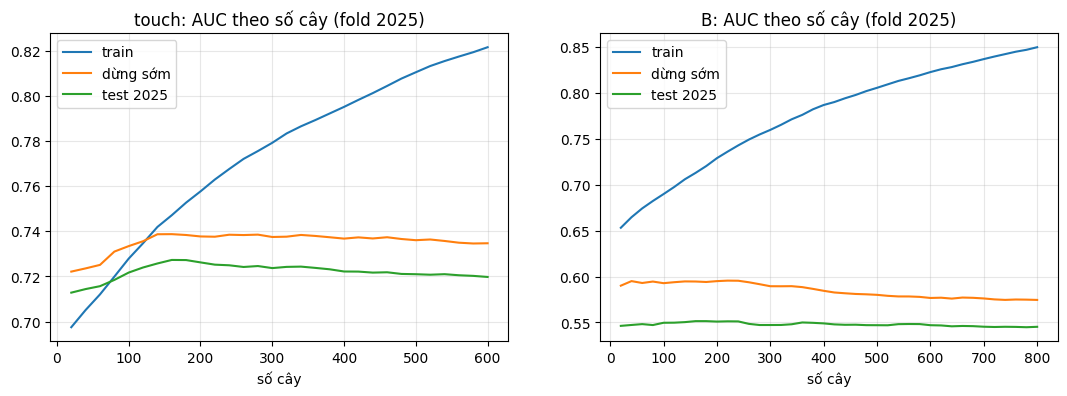

In [3]:
lc = ev.learning_curve(sd, cfg, year=2025)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, a in zip(('touch', 'B'), ax):
    for part, lab in (('tr', 'train'), ('es', 'dừng sớm'), ('te', 'test 2025')):
        a.plot(lc['số cây'], lc[f'{k} {part}'], label=lab)
    a.set_title(f'{k}: AUC theo số cây (fold 2025)'); a.set_xlabel('số cây'); a.legend(); a.grid(alpha=.3)
plt.show()

## 2. Model có học thật không

**Null xáo nhãn** (train lại 20 lần với nhãn train/dừng sớm bị xáo, đo AUC test):
- `iid`: xáo từng mẫu → model thuần nhiễu, AUC ≈ 0.5.
- `ngày`: hoán đổi nguyên ngày, giữ giờ trong ngày → giữ được mùa vụ theo giờ; AUC null của touch > 0.5 cho thấy phần AUC đến từ **giờ trong ngày**. Model thật phải vượt null này.

In [4]:
null_iid = ev.permutation_null(sd, cfg, n_perm=20, mode='iid')
null_day = ev.permutation_null(sd, cfg, n_perm=20, mode='ngày')
pd.concat([null_iid, null_day]).round(3)

,năm,kiểu xáo,touch AUC thật,touch AUC xáo (TB),touch AUC xáo (max),touch p,B AUC thật,B AUC xáo (TB),B AUC xáo (max),B p
0,2023,iid,0.636,0.502,0.562,0.048,0.597,0.497,0.545,0.048
1,2024,iid,0.737,0.497,0.539,0.048,0.595,0.498,0.548,0.048
2,2025,iid,0.722,0.499,0.563,0.048,0.552,0.502,0.536,0.048
0,2023,ngày,0.636,0.562,0.613,0.048,0.597,0.487,0.548,0.048
1,2024,ngày,0.737,0.606,0.635,0.048,0.595,0.498,0.549,0.048
2,2025,ngày,0.722,0.588,0.603,0.048,0.552,0.491,0.519,0.048


**So với model đơn giản:** logistic trên cùng feature và feature đơn tốt nhất (chọn trên train).

In [5]:
bl = ev.baselines(sd, cfg)
bl.round(3)

,năm,model,XGBoost,logistic,feature đơn tốt nhất,tên feature đơn
0,2023,touch,0.636,0.613,0.517,w12_up
1,2023,B,0.597,0.602,0.587,p_acct_ls_z7d
2,2024,touch,0.737,0.695,0.628,w6_rng
3,2024,B,0.595,0.597,0.598,p_acct_ls_z7d
4,2025,touch,0.722,0.703,0.621,dow_sin
5,2025,B,0.552,0.539,0.541,p_acct_ls_z7d


**Model B – bỏ nhóm feature:** chỉ giá / giá + có hướng / chỉ vị thế / có hướng + vị thế.

In [ ]:
ab = ev.dir_ablation(sd, cfg)
ab.round(3)

**Mức đóng góp theo nhóm** (AUC test giảm khi xáo cả nhóm feature).

In [ ]:
gi = ev.group_permutation_importance(sd, cfg)
gi.round(4)

**Theo nhóm xác suất (test 2023–2025 gộp):** touch – tỉ lệ chạm thực tế theo 10 nhóm p_touch; B – tỉ lệ đúng hướng theo 10 nhóm độ tự tin trên các giờ touch top 20% đã chạm.

In [ ]:
dec_t, dec_b = ev.decile_tables(sd, cfg)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(dec_t.p_TB, dec_t['tỉ_lệ_chạm'], 'o-'); ax[0].plot([0, 1], [0, 1], 'k--', lw=.8)
ax[0].set_title('touch: xác suất dự báo vs tỉ lệ chạm thực tế'); ax[0].set_xlabel('p_touch TB'); ax[0].grid(alpha=.3)
ax[1].bar(dec_b.index, dec_b['tỉ_lệ_đúng']); ax[1].axhline(.5, color='k', lw=.8)
ax[1].set_title('B: tỉ lệ đúng hướng theo nhóm độ tự tin'); ax[1].set_xlabel('nhóm (10 = tự tin nhất)'); ax[1].set_ylim(.4, .75)
plt.show()
display(dec_t.round(3), dec_b.round(3), dec_b.attrs['theo năm (top 10% vs còn lại)'].round(3))

## 3. Tối ưu tham số (chọn theo calibration, test chỉ để xem)
Tương quan giữa điểm calibration và điểm test cho biết việc tinh chỉnh có thực sự mang lại cải thiện ngoài mẫu không.

In [ ]:
tune_t = ev.tune(sd, cfg, 'touch', ev.TOUCH_GRID)
tune_b = ev.tune(sd, cfg, 'B', ev.DIR_GRID)
print('touch: tương quan cal ↔ test =', round(tune_t[['cal TB', 'test TB (chỉ xem)']].corr().iloc[0, 1], 2))
print('B:     tương quan cal ↔ test =', round(tune_b[['cal TB', 'test TB (chỉ xem)']].corr().iloc[0, 1], 2))
display(tune_t.head(5).round(4), tune_b.head(5).round(4))

In [ ]:
bt, bb_ = tune_t.iloc[0], tune_b.iloc[0]
cfg_tuned = replace(cfg,
    touch_xgb={k: (int(bt[k]) if k == 'max_depth' else float(bt[k])) for k in ev.TOUCH_GRID},
    dir_xgb={k: (int(bb_[k]) if k == 'max_depth' else float(bb_[k])) for k in ev.DIR_GRID if k != 'dir_features'},
    dir_features=bb_['dir_features'])
print('touch:', cfg_tuned.touch_xgb); print('B:', cfg_tuned.dir_xgb, cfg_tuned.dir_features)

## 4. Cách giao dịch và ngưỡng
Lưới: touch top {10, 20, 30, 50, 100%} × độ tự tin B top {3, 5, 10, 15, 20, 30%} × TP {0.75, 1, 1.25}b × SL {0.5, 0.6, 0.75, 1}b × thoát nhanh {tắt, 0.75%, 1%} × số lệnh tối đa {1, 3, 5, 8}. Mô phỏng trên nến 5m, R tính theo SL, phí 0.1%. `MODEL_CFG` chọn model dùng cho phần này.

In [ ]:
MODEL_CFG = cfg_tuned          # hoặc cfg (tham số mặc định)
fp = ev.fold_predictions(sd, MODEL_CFG)
sim = ev.Sim5m(candles_5m)
G = ev.trade_grid(sd, fp, sim)               # chỉ 2023-2025
print(len(G), 'cấu hình')

In [ ]:
C = G[(G.tp_mult == 1.0) & (G.max_positions == 5)]
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, v in zip(ax, ('tổng R', 'sụt giảm R', 'tổng R / sụt giảm')):
    t = C.pivot_table(index='touch_top', columns='dir_top', values=v)
    im = a.imshow(t.values, cmap='RdYlGn' if v != 'sụt giảm R' else 'RdYlGn_r', aspect='auto')
    a.set_xticks(range(t.shape[1]), t.columns); a.set_yticks(range(t.shape[0]), t.index)
    a.set_xlabel('B top'); a.set_ylabel('touch top'); a.set_title(f'{v} (TB theo SL/thoát nhanh; TP 1b, 5 lệnh)')
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            a.text(j, i, f'{t.values[i, j]:.0f}' if v != 'tổng R / sụt giảm' else f'{t.values[i, j]:.1f}', ha='center', va='center', fontsize=8)
plt.tight_layout(); plt.show()
marg = pd.concat({a: G.groupby(a)[['lệnh', 'R/lệnh', 'tổng R', 'sụt giảm R', 'tổng R / sụt giảm', 'năm kém nhất R']].mean()
                  for a in ('touch_top', 'dir_top', 'tp_mult', 'sl_mult', 'anomaly', 'max_positions')})
marg.round(2)        # trung bình theo từng trục (các trục khác lấy trung bình)

**Chọn theo vùng ổn định** (`ev.plateau`): điểm của một ô = trung bình điểm của ô đó và mọi ô lân cận (lệch ≤ 1 bậc mỗi trục). Đủ điều kiện = mọi năm 2023–2025 dương và ≥ 80% ô lân cận cũng mọi năm dương.
Ràng buộc thiết kế: TP = 1b (touch dự báo b), tối đa 5 lệnh. Bảng dưới so các tiêu chí điểm khác nhau.

In [ ]:
AX = ('touch_top', 'dir_top', 'sl_mult', 'anomaly', 'max_positions')
Cc = G[(G.tp_mult == 1.0) & (G.max_positions <= 5)]
rules = ev.selection_rules(Cc, AX)
rules.round(3)

**Độ bền thứ hạng cấu hình giữa các năm:** nếu cấu hình tốt năm này cũng tốt năm khác thì tương quan cao. Tương quan thấp nghĩa là chọn 'cấu hình tốt nhất' phần lớn là chọn nhiễu – nên ưu tiên vùng rộng, nhiều lệnh.

In [ ]:
ev.rank_stability(G, ev.SEL_YEARS, fixed={'tp_mult': 1.0, 'max_positions': 5}).round(2)

## 5. So với giao dịch ngẫu nhiên (cấu hình theo tiêu chí tổng R / sụt giảm)
(a) cùng giờ tín hiệu, hướng ngẫu nhiên – kiểm định model B; (b) giờ touch cao ngẫu nhiên, hướng của B – kiểm định bộ lọc độ tự tin; (c) giờ và hướng ngẫu nhiên – kiểm định cả hệ thống. 500 lần mỗi loại.

In [ ]:
pick = rules.iloc[0]
conf = {k: pick[k] for k in ('touch_top', 'dir_top', 'tp_mult', 'sl_mult', 'max_positions')} | {'anomaly': pick['anomaly']}
N = ev.random_nulls(sd, fp, sim, conf, n=500)
print('thật:', {k: round(v, 3) for k, v in N['thật'].items()})
fig, ax = plt.subplots(1, 3, figsize=(16, 3.5))
for a, k in zip(ax, ('a', 'b', 'c')):
    a.hist(N[k]['tổng R'], bins=40, color='grey'); a.axvline(N['thật']['tổng R'], color='r')
    a.set_title(N['tóm tắt'].null.iloc['abc'.index(k)], fontsize=9)
plt.show(); N['tóm tắt'].round(4)

## 6. 2026 (chỉ báo cáo – không dùng để chọn; đã từng được xem ở các phiên trước)

In [ ]:
G26 = ev.trade_grid(sd, fp, sim, years=(2026,))
key = list(ev.GRID)
rep = rules[['tiêu chí'] + key + ['lệnh', 'tổng R', 'sụt giảm R']].merge(
    G26[key + ['lệnh', 'R/lệnh', 'tổng R', 'sụt giảm R']], on=key, suffixes=(' 23-25', ' 2026'))
display(rep.round(3))
M = G.merge(G26[key + ['tổng R']].rename(columns={'tổng R': 'R 2026'}), on=key)
display(M[(M.tp_mult == 1) & (M.max_positions == 5)][['R 2023', 'R 2024', 'R 2025', 'R 2026']].corr('spearman').round(2))
display(G26[(G26.tp_mult == 1) & (G26.max_positions == 5)].pivot_table(index='touch_top', columns='dir_top', values='tổng R').round(1))

In [ ]:
# lưu kết quả
from pathlib import Path
out = Path('artifacts/1h_eval'); out.mkdir(parents=True, exist_ok=True)
for nm, d in {'overfit': ov, 'learning_curve': lc, 'null_iid': null_iid, 'null_day': null_day, 'baselines': bl,
              'dir_ablation': ab, 'deciles_touch': dec_t, 'deciles_B': dec_b, 'tune_touch': tune_t, 'tune_B': tune_b,
              'trade_grid_2023_2025': G, 'trade_grid_2026': G26, 'selection_rules': rules, 'nulls_summary': N['tóm tắt']}.items():
    d.to_csv(out / f'{nm}.csv', index=nm.startswith('deciles'))
gi.to_csv(out / 'group_importance.csv')
print('đã lưu', out)